<a href="https://colab.research.google.com/github/brajesh995/231FA04C59_MLOPS/blob/main/MLLab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train (1).csv


In [ ]:
df = pd.read_csv("train.csv")

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [ ]:
df.shape

(891, 12)

In [ ]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].median())

In [ ]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [ ]:
df.drop('Cabin', axis=1, inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df['Sex'] = df['Sex'].map({'male':0,'female':1})

In [ ]:
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

In [ ]:
df.drop(['PassengerId','Name','Ticket'], axis=1, inplace=True)

<Axes: ylabel='Age'>

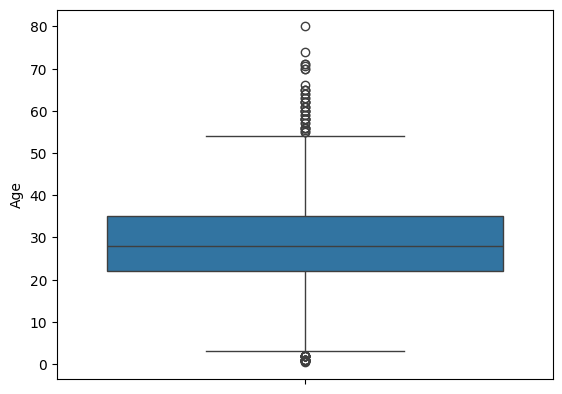

In [ ]:
sns.boxplot(df['Age'])

<Axes: ylabel='Fare'>

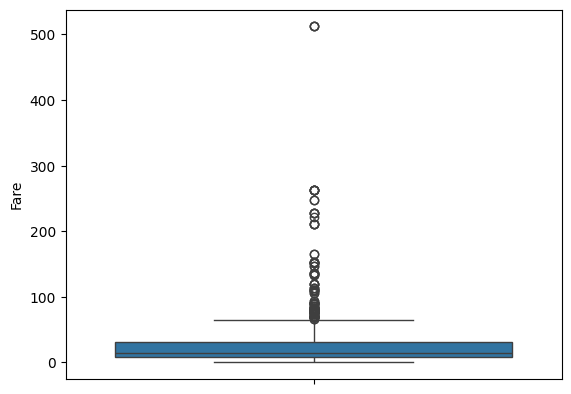

In [ ]:
sns.boxplot(df['Fare'])

In [ ]:
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[(df['Fare']>=lower) & (df['Fare']<=upper)]

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['Age','Fare']] = scaler.fit_transform(df[['Age','Fare']])

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[['Age','Fare']] = scaler.fit_transform(df[['Age','Fare']])

In [ ]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,0.271174,1,0,0.111538,False,True
2,1,3,1,0.321438,0,0,0.121923,False,True
3,1,1,1,0.434531,1,0,0.816923,False,True
4,0,3,0,0.434531,0,0,0.123846,False,True
5,0,3,0,0.346569,0,0,0.130128,True,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 775 entries, 0 to 890
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    775 non-null    int64  
 1   Pclass      775 non-null    int64  
 2   Sex         775 non-null    int64  
 3   Age         775 non-null    float64
 4   SibSp       775 non-null    int64  
 5   Parch       775 non-null    int64  
 6   Fare        775 non-null    float64
 7   Embarked_Q  775 non-null    bool   
 8   Embarked_S  775 non-null    bool   
dtypes: bool(2), float64(2), int64(5)
memory usage: 50.0 KB


In [ ]:
df.describe()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
count,775.000000,775.00000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,0.339355,2.48000,0.314839,0.355978,0.437419,0.340645,0.274186
std,0.473796,0.73439,0.464752,0.160620,0.899838,0.785914,0.208894
min,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.00000,0.000000,0.271174,0.000000,0.000000,0.121474
50%,0.000000,3.00000,0.000000,0.346569,0.000000,0.000000,0.200000
75%,1.000000,3.00000,1.000000,0.421965,1.000000,0.000000,0.400000
max,1.000000,3.00000,1.000000,1.000000,5.000000,6.000000,1.000000


In [ ]:
df.to_csv("Titanic_Preprocessed.csv", index=False)

In [ ]:
# Reload the original data for pipeline demonstration

df_raw = pd.read_csv("train.csv")



# Separate target variable from features

X_raw = df_raw.drop('Survived', axis=1)

y_raw = df_raw['Survived']



print("Original raw data info:")

X_raw.info()

Original raw data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Pclass       891 non-null    int64  
 2   Name         891 non-null    object 
 3   Sex          891 non-null    object 
 4   Age          714 non-null    float64
 5   SibSp        891 non-null    int64  
 6   Parch        891 non-null    int64  
 7   Ticket       891 non-null    object 
 8   Fare         891 non-null    float64
 9   Cabin        204 non-null    object 
 10  Embarked     889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 76.7+ KB


In [ ]:
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler



# Define numerical and categorical features

numerical_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']

categorical_features_onehot = ['Embarked']



# Create a transformer for numerical features

numerical_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', MinMaxScaler())

])



# Create a transformer for categorical features

categorical_onehot_transformer = Pipeline(steps=[

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))

])



# Define the column transformer

preprocessor = ColumnTransformer(

    transformers=[

        ('num', numerical_transformer, ['Age', 'Fare']),

        ('cat_onehot', categorical_onehot_transformer, categorical_features_onehot),

        ('sex_map', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), ['Sex'])

    ],

    remainder='drop'

)



# Create the full preprocessing pipeline

full_pipeline = Pipeline(steps=[

    ('preprocessor', preprocessor)

])



# Fit and transform the raw data

X_processed_pipeline = full_pipeline.fit_transform(X_raw)



# Extract feature names

num_cols = ['Age', 'Fare']

cat_transformer = full_pipeline.named_steps['preprocessor'].named_transformers_['cat_onehot']

cat_cols = list(cat_transformer.named_steps['onehot'].get_feature_names_out(categorical_features_onehot))

sex_transformer = full_pipeline.named_steps['preprocessor'].named_transformers_['sex_map']

sex_cols = list(sex_transformer.get_feature_names_out(['Sex']))



feature_names = num_cols + cat_cols + sex_cols

df_pipeline_processed = pd.DataFrame(X_processed_pipeline, columns=feature_names)



display(df_pipeline_processed.head())

,Age,Fare,Embarked_Q,Embarked_S,Sex_male
0,0.271174,0.014151,0.0,1.0,1.0
1,0.472229,0.139136,0.0,0.0,0.0
2,0.321438,0.015469,0.0,1.0,0.0
3,0.434531,0.103644,0.0,1.0,0.0
4,0.434531,0.015713,0.0,1.0,1.0


In [ ]:
df_pipeline_processed.to_csv("Titanic_Preprocessed_Pipeline.csv", index=False)

print("Pipeline processed dataset saved as 'Titanic_Preprocessed_Pipeline.csv'")

Pipeline processed dataset saved as 'Titanic_Preprocessed_Pipeline.csv'
